## Student marks prediction

In [1]:
# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Load the dataset 
df = pd.read_excel("Student marks prediction.xlsx")
df

,Student_ID,Student_Name,Hours_Studied,Attendance,Previous_Marks,Sleep_Hours,Practice_Tests,Extracurricular,Final_Marks
0,STU001,Aarav,2,65,45,6,1,No,42
1,STU002,Diya,3,70,50,7,2,Yes,50
2,STU003,Rohan,4,75,55,7,2,No,56
3,STU004,Anaya,5,80,60,8,3,Yes,65
4,STU005,Kabir,6,85,65,7,4,No,70
5,STU006,Meera,7,90,70,8,5,Yes,78
6,STU007,Arjun,8,92,75,8,5,No,83
7,STU008,Isha,9,95,80,7,6,Yes,90
8,STU009,Vivaan,3,68,48,6,1,No,46
9,STU010,Saanvi,5,78,58,7,3,Yes,62


In [3]:
# Check column names 
print(df.columns)

Index(['Student_ID', 'Student_Name', 'Hours_Studied', 'Attendance',
       'Previous_Marks', 'Sleep_Hours', 'Practice_Tests', 'Extracurricular',
       'Final_Marks'],
      dtype='object')


In [4]:
# Check the dataset shape 
print(df.shape)

(30, 9)


In [5]:
# Check dataset information 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Student_ID       30 non-null     object
 1   Student_Name     30 non-null     object
 2   Hours_Studied    30 non-null     int64 
 3   Attendance       30 non-null     int64 
 4   Previous_Marks   30 non-null     int64 
 5   Sleep_Hours      30 non-null     int64 
 6   Practice_Tests   30 non-null     int64 
 7   Extracurricular  30 non-null     object
 8   Final_Marks      30 non-null     int64 
dtypes: int64(6), object(3)
memory usage: 2.2+ KB


In [6]:
# Statistical Summary 
df.describe()

,Hours_Studied,Attendance,Previous_Marks,Sleep_Hours,Practice_Tests,Final_Marks
count,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000
mean,5.700000,81.533333,63.466667,7.166667,3.766667,68.100000
std,2.070316,10.180215,12.420043,0.746640,1.794308,15.772849
min,2.000000,60.000000,40.000000,6.000000,1.000000,39.000000
25%,4.000000,74.250000,54.250000,7.000000,2.000000,55.250000
50%,6.000000,82.500000,62.500000,7.000000,4.000000,68.000000
75%,7.000000,89.750000,72.750000,8.000000,5.000000,79.750000
max,9.000000,97.000000,88.000000,8.000000,7.000000,95.000000


In [7]:
# Check missing values 
df.isnull().sum()

Student_ID         0
Student_Name       0
Hours_Studied      0
Attendance         0
Previous_Marks     0
Sleep_Hours        0
Practice_Tests     0
Extracurricular    0
Final_Marks        0
dtype: int64

In [8]:
# Check duplicate records 
df.duplicated().sum()

np.int64(0)

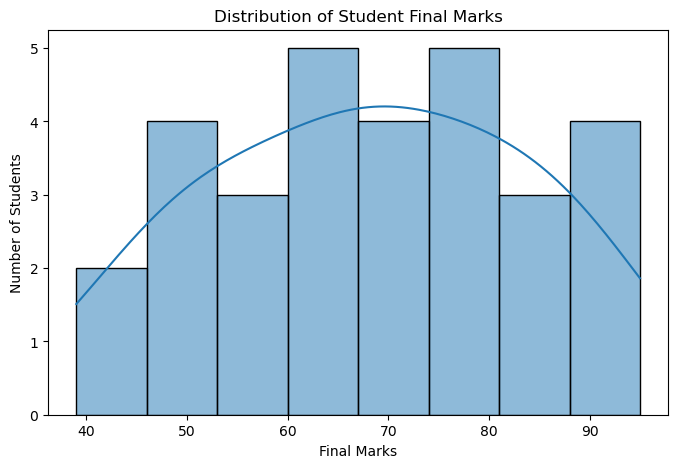

In [9]:
# Data Visualization – Distribution of Final Marks 
plt.figure(figsize=(8, 5))

sns.histplot(df['Final_Marks'], bins=8, kde=True)

plt.title('Distribution of Student Final Marks')
plt.xlabel('Final Marks')
plt.ylabel('Number of Students')

plt.show()

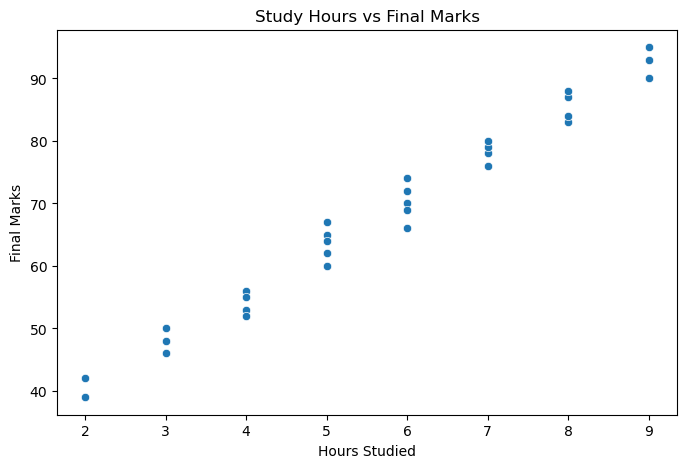

In [10]:
# Study Hours vs Final Marks 
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Hours_Studied',
    y='Final_Marks'
)

plt.title('Study Hours vs Final Marks')
plt.xlabel('Hours Studied')
plt.ylabel('Final Marks')

plt.show()

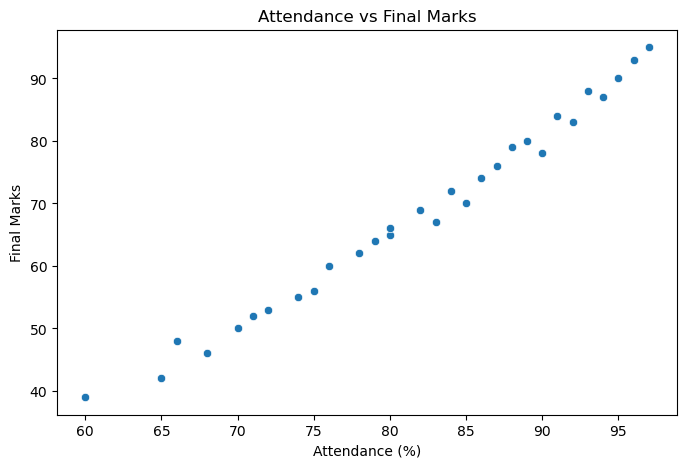

In [11]:
# Attendance vs Final Marks 
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Attendance',
    y='Final_Marks'
)

plt.title('Attendance vs Final Marks')
plt.xlabel('Attendance (%)')
plt.ylabel('Final Marks')

plt.show()

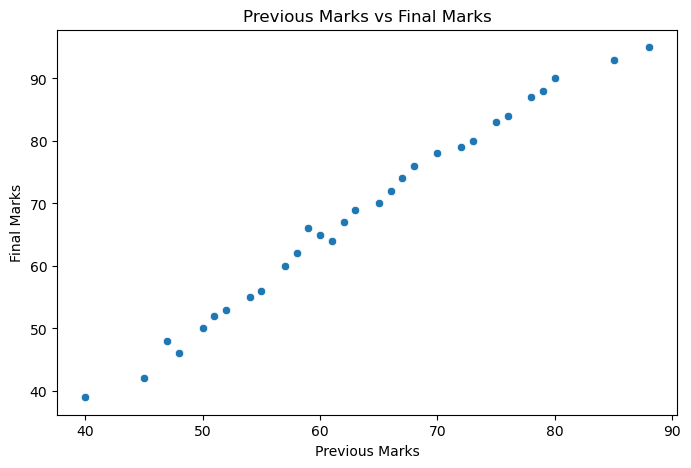

In [12]:
# Previous Marks vs Final Marks 
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Previous_Marks',
    y='Final_Marks'
)

plt.title('Previous Marks vs Final Marks')
plt.xlabel('Previous Marks')
plt.ylabel('Final Marks')

plt.show()

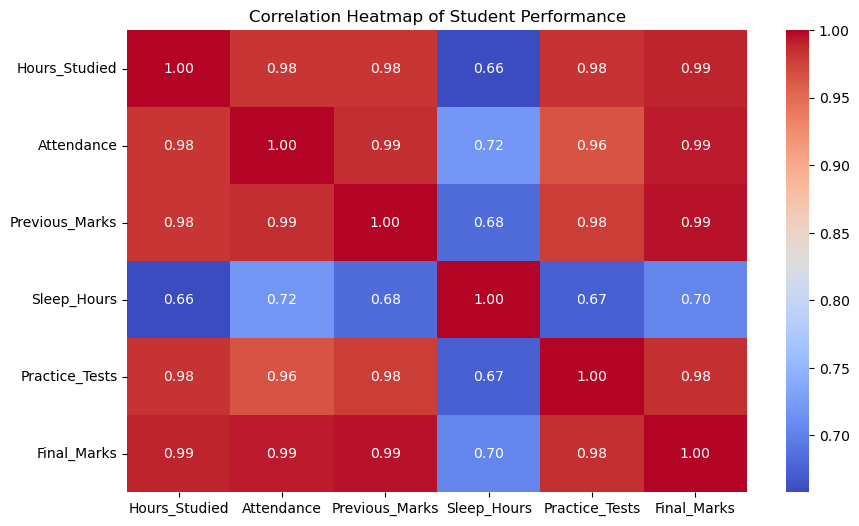

In [13]:
# Correlation Heatmap 
plt.figure(figsize=(10, 6))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Student Performance')

plt.show()

In [14]:
# Drop unnecesary columns 

df = df.drop(['Student_ID', 'Student_Name'], axis=1) 
df.head()

,Hours_Studied,Attendance,Previous_Marks,Sleep_Hours,Practice_Tests,Extracurricular,Final_Marks
0,2,65,45,6,1,No,42
1,3,70,50,7,2,Yes,50
2,4,75,55,7,2,No,56
3,5,80,60,8,3,Yes,65
4,6,85,65,7,4,No,70


In [15]:
# Separate input features and target variable

X = df.drop('Final_Marks', axis=1)

y = df['Final_Marks']

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

Input Features Shape: (30, 6)
Target Variable Shape: (30,)


In [16]:
# Convert Yes/No into 1/0

X['Extracurricular'] = X['Extracurricular'].map({
    'Yes': 1,
    'No': 0
})

X.head()

,Hours_Studied,Attendance,Previous_Marks,Sleep_Hours,Practice_Tests,Extracurricular
0,2,65,45,6,1,0
1,3,70,50,7,2,1
2,4,75,55,7,2,0
3,5,80,60,8,3,1
4,6,85,65,7,4,0


In [17]:
# Split dataset into training and testing data 
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (24, 6)
X_test: (6, 6)
y_train: (24,)
y_test: (6,)


In [18]:
# Import Linear Regression
from sklearn.linear_model import LinearRegression

# Create the model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [19]:
# Make Predictions 
# Predict final marks
y_pred_lr = lr_model.predict(X_test)

# Compare actual and predicted marks
comparison = pd.DataFrame({
    'Actual Marks': y_test.values,
    'Predicted Marks': y_pred_lr
})

print(comparison)

   Actual Marks  Predicted Marks
0            64        64.077469
1            39        38.285971
2            72        71.615761
3            67        66.655547
4            46        46.807324
5            62        62.208975


In [22]:
# Evaluate linear regression model 
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred_lr)
mse = mean_squared_error(y_test, y_pred_lr)
r2 = r2_score(y_test, y_pred_lr)

print("Linear Regression Results")
print("MAE:", mae)
print("MSE:", mse)
print("R2 Score:", r2)

Linear Regression Results
MAE: 0.42274819813666537
MSE: 0.24626144060587032
R2 Score: 0.9982269176276377


In [23]:
# Decission Tree Regression 
from sklearn.tree import DecisionTreeRegressor

# Create the model
dt_model = DecisionTreeRegressor(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [24]:
# Make predictions using decision tree 
# Predict final marks
y_pred_dt = dt_model.predict(X_test)

# Compare actual and predicted marks
dt_comparison = pd.DataFrame({
    'Actual Marks': y_test.values,
    'Predicted Marks': y_pred_dt
})

print(dt_comparison)

   Actual Marks  Predicted Marks
0            64             65.0
1            39             42.0
2            72             74.0
3            67             74.0
4            46             48.0
5            62             66.0


In [25]:
# Evaluate decision tree regression 
# Calculate evaluation metrics

mae_dt = mean_absolute_error(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)
r2_dt = r2_score(y_test, y_pred_dt)

print("Decision Tree Results")
print("MAE:", mae_dt)
print("MSE:", mse_dt)
print("R2 Score:", r2_dt)

Decision Tree Results
MAE: 3.1666666666666665
MSE: 13.833333333333334
R2 Score: 0.9004


In [26]:
# Random forest regression 
from sklearn.ensemble import RandomForestRegressor

# Create the model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [27]:
# Make Predictions using random forest 
# Predict final marks
y_pred_rf = rf_model.predict(X_test)

# Compare actual and predicted marks
rf_comparison = pd.DataFrame({
    'Actual Marks': y_test.values,
    'Predicted Marks': y_pred_rf
})

print(rf_comparison)

   Actual Marks  Predicted Marks
0            64            63.05
1            39            45.13
2            72            70.90
3            67            65.62
4            46            47.79
5            62            60.92


In [28]:
# Evaluate random forest regression 
# Calculate evaluation metrics

mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("MAE:", mae_rf)
print("MSE:", mse_rf)
print("R2 Score:", r2_rf)

Random Forest Results
MAE: 2.0716666666666654
MSE: 7.660716666666667
R2 Score: 0.94484284


In [29]:
# Comparing all three models
# Calculate evaluation metrics

mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("MAE:", mae_rf)
print("MSE:", mse_rf)
print("R2 Score:", r2_rf)

Random Forest Results
MAE: 2.0716666666666654
MSE: 7.660716666666667
R2 Score: 0.94484284


In [34]:
# Model comparison 
model_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'MAE': [mae, mae_dt, mae_rf],
    'MSE': [mse, mse_dt, mse_rf],
    'R2 Score': [r2, r2_dt, r2_rf]
})

print(model_comparison)

               Model       MAE        MSE  R2 Score
0  Linear Regression  0.422748   0.246261  0.998227
1      Decision Tree  3.166667  13.833333  0.900400
2      Random Forest  2.071667   7.660717  0.944843


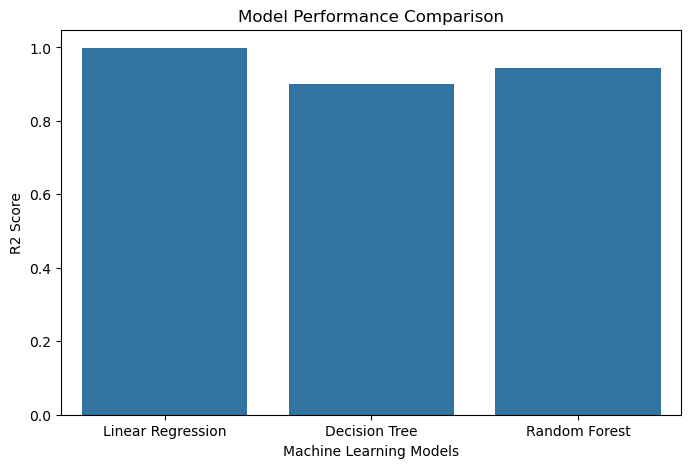

In [35]:
# Visualization 
plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x='Model',
    y='R2 Score'
)

plt.title('Model Performance Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('R2 Score')
plt.show()

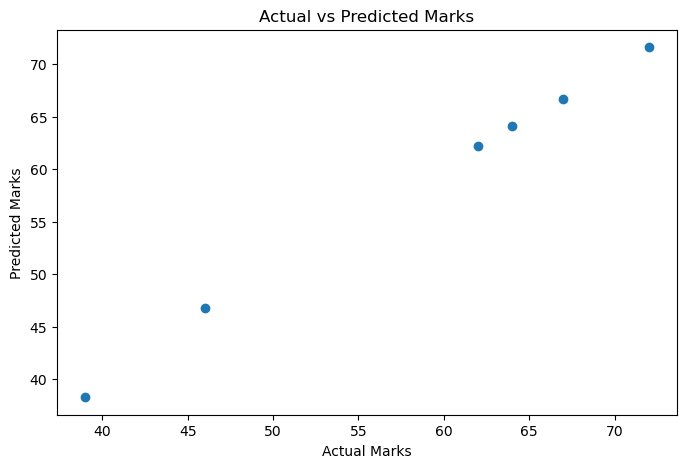

In [36]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_lr)

plt.xlabel('Actual Marks')
plt.ylabel('Predicted Marks')
plt.title('Actual vs Predicted Marks')

plt.show()

In [37]:
# Predict marks for new student
new_student = pd.DataFrame({
    'Hours_Studied': [5],
    'Attendance': [85],
    'Previous_Marks': [70],
    'Sleep_Hours': [7],
    'Practice_Tests': [4],
    'Extracurricular': [1]
})

predicted_marks = lr_model.predict(new_student)

print("Predicted Final Marks:", predicted_marks[0])

Predicted Final Marks: 72.13993101399885


In [38]:
# Save the trained model 
import pickle

with open('student_marks_model.pkl', 'wb') as file:
    pickle.dump(lr_model, file)

print("Model saved successfully!")

Model saved successfully!


In [40]:
# Load the saved model 
with open('student_marks_model.pkl', 'rb') as file:
    loaded_model = pickle.load(file)

print("Model loaded successfully!")

Model loaded successfully!


In [41]:
# Test the loaded model 
loaded_prediction = loaded_model.predict(new_student)

print("Predicted Final Marks:", loaded_prediction[0])

Predicted Final Marks: 72.13993101399885
